In [1]:
# Manipulação e análise de dados
import pandas as pd
import numpy as np

# Visualização dos dados
import matplotlib.pyplot as plt
import seaborn as sns

# Interpolação e cálculos estatísticos
from scipy import stats

# Manipulação de caminhos e diretórios
from pathlib import Path

# Configurações de visualização
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.3f}".format)

sns.set_theme(style="whitegrid")

print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


In [3]:
from pathlib import Path

# Caminho do arquivo CSV original (não será alterado)
ARQUIVO_ORIGINAL = Path(
    r"C:\Users\adriel_soares2\Documents\Projeto_Aero\data\raw\dados_sensores_aeromotion.csv"
)

# Caminho de destino do arquivo CSV tratado
ARQUIVO_TRATADO = Path(
    r"C:\Users\adriel_soares2\Documents\Projeto_Aero\data\processed\dados_sensores_aeromotion_tratados.csv"
)

# Verifica se o arquivo original existe
if not ARQUIVO_ORIGINAL.exists():
    raise FileNotFoundError(
        f"Arquivo original não encontrado: {ARQUIVO_ORIGINAL}"
    )

# Cria a pasta de destino caso ela ainda não exista
ARQUIVO_TRATADO.parent.mkdir(parents=True, exist_ok=True)

print(f"Arquivo original: {ARQUIVO_ORIGINAL}")
print(f"Arquivo tratado: {ARQUIVO_TRATADO}")
print("Caminhos configurados corretamente.")

Arquivo original: C:\Users\adriel_soares2\Documents\Projeto_Aero\data\raw\dados_sensores_aeromotion.csv
Arquivo tratado: C:\Users\adriel_soares2\Documents\Projeto_Aero\data\processed\dados_sensores_aeromotion_tratados.csv
Caminhos configurados corretamente.


In [4]:
import pandas as pd

# Lê o CSV original sem modificá-lo
df_original = pd.read_csv(ARQUIVO_ORIGINAL)

# Cria uma cópia para executar o tratamento
df = df_original.copy(deep=True)

print(f"Dimensões do arquivo original: {df_original.shape}")

Dimensões do arquivo original: (12000, 11)


In [5]:
# Exibe os nomes das colunas para conferir o dicionário de dados
print("Colunas disponíveis:")
print(df.columns.tolist())

# Analisa os tipos de dados e a quantidade de valores preenchidos
df.info()

# Estatísticas descritivas das variáveis numéricas
display(df.describe(include="all").T)

# Quantidade de valores ausentes por coluna
ausentes = pd.DataFrame({
    "valores_ausentes": df.isna().sum(),
    "percentual_ausente": df.isna().mean().mul(100)
})

display(ausentes.sort_values(
    "percentual_ausente",
    ascending=False
))

Colunas disponíveis:
['timestamp', 'id_equipamento', 'modo_operacao', 'horas_operacao_acumuladas', 'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp', 'tipo_falha']
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   timestamp                  12000 non-null  str    
 1   id_equipamento             12000 non-null  str    
 2   modo_operacao              12000 non-null  str    
 3   horas_operacao_acumuladas  12000 non-null  float64
 4   temperatura_mancal_c       11591 non-null  float64
 5   vibracao_rms_mms           11648 non-null  float64
 6   pressao_oleo_bar           11672 non-null  float64
 7   rotacao_rpm                12000 non-null  float64
 8   emissao_acustica_db        11516 non-null  float64
 9   corrente_eletrica_amp      12000 non-null

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,12000,12000,2026-01-01 00:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id_equipamento,12000,4,TURB-101,3043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
modo_operacao,12000,3,Carga_Media,6024,NaN,NaN,NaN,NaN,NaN,NaN,NaN
horas_operacao_acumuladas,12000.000,NaN,NaN,NaN,2309.755,1263.758,100.200,1227.675,2317.300,3386.025,4499.600
temperatura_mancal_c,11591.000,NaN,NaN,NaN,68.694,66.781,40.000,58.060,63.150,69.765,999.900
vibracao_rms_mms,11648.000,NaN,NaN,NaN,3.010,6.752,-99.000,2.180,2.700,3.720,15.170
pressao_oleo_bar,11672.000,NaN,NaN,NaN,4.231,0.589,0.680,3.960,4.240,4.610,5.590
rotacao_rpm,12000.000,NaN,NaN,NaN,3031.155,383.231,2278.200,2950.300,3010.500,3461.500,3641.400
emissao_acustica_db,11516.000,NaN,NaN,NaN,54.805,9.208,34.150,49.250,52.970,60.660,104.000
corrente_eletrica_amp,12000.000,NaN,NaN,NaN,30.058,7.321,15.350,26.250,28.530,37.010,62.540


,valores_ausentes,percentual_ausente
emissao_acustica_db,484,4.033
temperatura_mancal_c,409,3.408
vibracao_rms_mms,352,2.933
pressao_oleo_bar,328,2.733
modo_operacao,0,0.000
timestamp,0,0.000
id_equipamento,0,0.000
horas_operacao_acumuladas,0,0.000
rotacao_rpm,0,0.000
corrente_eletrica_amp,0,0.000


In [6]:
# Lista de colunas esperadas segundo o dicionário do projeto
COLUNAS_ESPERADAS = [
    "timestamp",
    "id_equipamento",
    "modo_operacao",
    "horas_operacao_acumuladas",
    "temperatura_mancal_c",
    "vibracao_rms_mms",
    "pressao_oleo_bar",
    "rotacao_rpm",
    "emissao_acustica_db",
    "corrente_eletrica_amp",
    "tipo_falha",
]

# Identifica diferenças entre o dicionário e o arquivo real
faltantes = sorted(set(COLUNAS_ESPERADAS) - set(df.columns))
extras = sorted(set(df.columns) - set(COLUNAS_ESPERADAS))

print("Colunas esperadas ausentes:", faltantes)
print("Colunas adicionais:", extras)

Colunas esperadas ausentes: []
Colunas adicionais: []


In [7]:
# Converte timestamp para datetime.
# Valores que não puderem ser interpretados serão identificados como NaT.
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

# Converte os sensores e demais medidas para valores numéricos.
# Strings inválidas serão transformadas em NaN para posterior tratamento.
COLUNAS_NUMERICAS = [
    "horas_operacao_acumuladas",
    "temperatura_mancal_c",
    "vibracao_rms_mms",
    "pressao_oleo_bar",
    "rotacao_rpm",
    "emissao_acustica_db",
    "corrente_eletrica_amp",
    "tipo_falha",
]

for coluna in COLUNAS_NUMERICAS:
    if coluna in df.columns:
        df[coluna] = pd.to_numeric(
            df[coluna],
            errors="coerce"
        )

# Exibe o resultado da conversão
display(df.dtypes.to_frame("tipo_de_dado"))

# Quantifica timestamps inválidos
print(
    "Timestamps inválidos:",
    df["timestamp"].isna().sum()
)

,tipo_de_dado
timestamp,datetime64[us]
id_equipamento,str
modo_operacao,str
horas_operacao_acumuladas,float64
temperatura_mancal_c,float64
vibracao_rms_mms,float64
pressao_oleo_bar,float64
rotacao_rpm,float64
emissao_acustica_db,float64
corrente_eletrica_amp,float64


Timestamps inválidos: 0


In [8]:
# Trabalha apenas com registros que possuem timestamp e equipamento válidos
df_validacao = df.dropna(
    subset=["timestamp", "id_equipamento"]
).copy()

# Ordena cronologicamente cada equipamento
df_validacao = df_validacao.sort_values(
    ["id_equipamento", "timestamp"]
)

# Calcula a diferença entre leituras consecutivas da mesma bancada
df_validacao["intervalo_minutos"] = (
    df_validacao
    .groupby("id_equipamento")["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(60)
)

# Distribuição dos intervalos encontrados
display(
    df_validacao["intervalo_minutos"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("intervalo_minutos")
    .to_frame("quantidade")
)

# Identifica intervalos diferentes de 10 minutos
intervalos_irregulares = df_validacao[
    df_validacao["intervalo_minutos"].notna()
    & ~np.isclose(
        df_validacao["intervalo_minutos"],
        10
    )
]

print(
    "Intervalos diferentes de 10 minutos:",
    len(intervalos_irregulares)
)

display(intervalos_irregulares.head(10))

,quantidade
intervalo_minutos,
10.000,2981
20.000,2336
30.000,1654
40.000,1252
50.000,905
60.000,705
70.000,539
80.000,399
90.000,316


Intervalos diferentes de 10 minutos: 9015


,timestamp,id_equipamento,modo_operacao,horas_operacao_acumuladas,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp,tipo_falha,intervalo_minutos
6,2026-01-01 01:00:00,TURB-101,Carga_Media,101.400,58.030,2.500,4.000,2925.200,52.830,27.750,0,40.000
15,2026-01-01 02:30:00,TURB-101,Carga_Media,106.400,64.110,13.470,4.190,3011.200,49.740,42.560,2,80.000
21,2026-01-01 03:30:00,TURB-101,Cruzeiro,109.200,49.550,1.280,4.080,2477.400,44.980,18.990,0,60.000
30,2026-01-01 05:00:00,TURB-101,Carga_Media,113.700,99.670,3.180,1.050,3013.200,50.100,27.960,3,90.000
35,2026-01-01 05:50:00,TURB-101,Carga_Alta,114.600,69.860,4.560,4.680,3515.900,58.850,39.020,0,40.000
37,2026-01-01 06:10:00,TURB-101,Cruzeiro,114.900,52.560,1.680,4.030,2452.600,42.220,18.650,0,20.000
57,2026-01-01 09:30:00,TURB-101,Carga_Media,125.000,58.540,2.310,NaN,2992.500,50.090,26.760,0,190.000
59,2026-01-01 09:50:00,TURB-101,Cruzeiro,125.700,57.400,2.110,3.680,2426.700,40.540,19.650,0,20.000
62,2026-01-01 10:20:00,TURB-101,Carga_Media,126.500,64.030,7.830,4.070,3015.700,51.720,43.440,2,30.000
67,2026-01-01 11:10:00,TURB-101,Carga_Media,128.700,57.770,1.970,4.380,3043.300,53.020,29.420,0,40.000


In [9]:
# Detecta mais de uma leitura da mesma bancada no mesmo instante
duplicados = df[
    df.duplicated(
        subset=["id_equipamento", "timestamp"],
        keep=False
    )
].sort_values(["id_equipamento", "timestamp"])

print("Registros com equipamento e timestamp duplicados:", len(duplicados))

display(duplicados.head(20))

Registros com equipamento e timestamp duplicados: 0


,timestamp,id_equipamento,modo_operacao,horas_operacao_acumuladas,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp,tipo_falha


,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp
id_equipamento,,,,,,
TURB-101,2.790,2.990,2.760,0.000,4.010,0.000
TURB-102,3.510,2.750,2.650,0.000,4.440,0.000
TURB-103,3.780,3.200,2.870,0.000,4.050,0.000
TURB-104,3.570,2.790,2.660,0.000,3.640,0.000


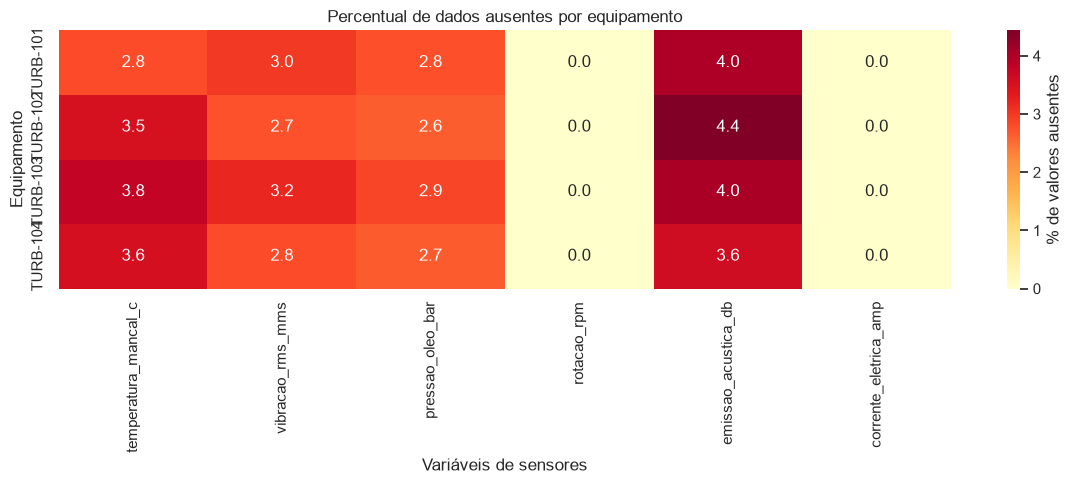

In [10]:
# Define as colunas de sensores que serão avaliadas
COLUNAS_SENSORES = [
    "temperatura_mancal_c",
    "vibracao_rms_mms",
    "pressao_oleo_bar",
    "rotacao_rpm",
    "emissao_acustica_db",
    "corrente_eletrica_amp",
]

COLUNAS_SENSORES = [
    coluna for coluna in COLUNAS_SENSORES
    if coluna in df.columns
]

# Calcula a taxa de ausência de cada sensor por equipamento
ausentes_por_equipamento = (
    df.groupby("id_equipamento")[COLUNAS_SENSORES]
    .agg(lambda serie: serie.isna().mean() * 100)
)

display(ausentes_por_equipamento.round(2))

# Visualiza o percentual de ausência por equipamento e variável
plt.figure(figsize=(12, 5))

sns.heatmap(
    ausentes_por_equipamento,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    cbar_kws={"label": "% de valores ausentes"}
)

plt.title("Percentual de dados ausentes por equipamento")
plt.xlabel("Variáveis de sensores")
plt.ylabel("Equipamento")
plt.tight_layout()
plt.show()

In [11]:
# Converte os artefatos explicitamente documentados em valores ausentes.
# A cópia original permanece preservada em df_original.

df.loc[
    np.isclose(df["temperatura_mancal_c"], 999.9, atol=1e-6),
    "temperatura_mancal_c"
] = np.nan

df.loc[
    np.isclose(df["vibracao_rms_mms"], -99.0, atol=1e-6),
    "vibracao_rms_mms"
] = np.nan

# Vibração RMS negativa não faz sentido físico como magnitude.
# Os valores negativos restantes são sinalizados como inválidos.
df.loc[
    df["vibracao_rms_mms"] < 0,
    "vibracao_rms_mms"
] = np.nan

print("Artefatos conhecidos tratados.")

Artefatos conhecidos tratados.


In [12]:
# Calcula Z-Score para inspecionar possíveis extremos.
# O Z-Score global é usado apenas para diagnóstico inicial.

COLUNAS_ZSCORE = [
    coluna for coluna in [
        "temperatura_mancal_c",
        "vibracao_rms_mms",
        "pressao_oleo_bar",
        "rotacao_rpm",
        "emissao_acustica_db",
        "corrente_eletrica_amp",
    ]
    if coluna in df.columns
]

resumo_zscore = []

for coluna in COLUNAS_ZSCORE:
    valores = df[coluna]

    media = valores.mean()
    desvio = valores.std()

    if pd.notna(desvio) and desvio > 0:
        zscore = (valores - media) / desvio
        suspeitos = zscore.abs() > 3
    else:
        suspeitos = pd.Series(False, index=df.index)

    resumo_zscore.append({
        "variavel": coluna,
        "quantidade_suspeita": int(suspeitos.sum()),
        "percentual_suspeito": float(suspeitos.mean() * 100),
    })

display(pd.DataFrame(resumo_zscore))

,variavel,quantidade_suspeita,percentual_suspeito
0,temperatura_mancal_c,233,1.942
1,vibracao_rms_mms,446,3.717
2,pressao_oleo_bar,285,2.375
3,rotacao_rpm,0,0.000
4,emissao_acustica_db,262,2.183
5,corrente_eletrica_amp,99,0.825


In [13]:
# Copia o conjunto já convertido e com artefatos conhecidos tratados
df_tratamento = df.copy()

# Mantém um registro dos valores ausentes antes da interpolação
ausentes_antes = df_tratamento[COLUNAS_SENSORES].isna().sum()

# Ordena as leituras para preservar a ordem temporal
df_tratamento = df_tratamento.sort_values(
    ["id_equipamento", "timestamp"]
)

def interpolar_por_equipamento(grupo):
    """
    Interpola pequenas lacunas internas de sensores usando o tempo.
    Cada equipamento é tratado de forma independente.
    """
    grupo = grupo.copy()

    # Usa timestamp como índice temporal para a interpolação
    grupo = grupo.set_index("timestamp")

    # Interpola somente lacunas internas de até 3 leituras consecutivas
    grupo[COLUNAS_SENSORES] = grupo[COLUNAS_SENSORES].interpolate(
        method="time",
        limit=3,
        limit_area="inside",
    )

    # Restaura timestamp como coluna
    return grupo.reset_index()

# Executa a interpolação separadamente em cada bancada
df_tratamento = (
    df_tratamento
    .groupby("id_equipamento", group_keys=False)
    .apply(interpolar_por_equipamento)
    .reset_index(drop=True)
)

# Compara o número de ausentes antes e depois
ausentes_depois = df_tratamento[COLUNAS_SENSORES].isna().sum()

comparacao_ausentes = pd.DataFrame({
    "antes": ausentes_antes,
    "depois": ausentes_depois,
})

comparacao_ausentes["preenchidos"] = (
    comparacao_ausentes["antes"]
    - comparacao_ausentes["depois"]
)

display(comparacao_ausentes)

,antes,depois,preenchidos
temperatura_mancal_c,467,0,467
vibracao_rms_mms,397,1,396
pressao_oleo_bar,328,0,328
rotacao_rpm,0,0,0
emissao_acustica_db,484,0,484
corrente_eletrica_amp,0,0,0


In [15]:
# Verifica se existem registros que impedem o agrupamento temporal correto
invalidos = df_tratamento[
    df_tratamento["timestamp"].isna()
    | df_tratamento["id_equipamento"].isna()
]

print("Registros sem timestamp ou equipamento:", len(invalidos))

# Verifica duplicatas após o tratamento
duplicados_tratados = df_tratamento[
    df_tratamento.duplicated(
        subset=["id_equipamento", "timestamp"],
        keep=False
    )
]

print("Leituras duplicadas:", len(duplicados_tratados))

# Interrompe a execução para evitar cálculos temporais incorretos
if not invalidos.empty:
    raise ValueError(
        "Existem registros sem timestamp ou equipamento. "
        "Investigue-os antes de continuar."
    )

if not duplicados_tratados.empty:
    raise ValueError(
        "Existem leituras duplicadas por equipamento e timestamp. "
        "Investigue-as antes de continuar."
    )

KeyError: 'id_equipamento'

In [16]:
# Verifica os nomes reais das colunas
print("Colunas:", [repr(coluna) for coluna in df.columns])

# Verifica se a coluna existe
print("Existe em df:", "id_equipamento" in df.columns)
print("Existe em df_original:", "id_equipamento" in df_original.columns)

# Verifica as primeiras linhas
display(df.head())

Colunas: ["'timestamp'", "'id_equipamento'", "'modo_operacao'", "'horas_operacao_acumuladas'", "'temperatura_mancal_c'", "'vibracao_rms_mms'", "'pressao_oleo_bar'", "'rotacao_rpm'", "'emissao_acustica_db'", "'corrente_eletrica_amp'", "'tipo_falha'"]
Existe em df: True
Existe em df_original: True


,timestamp,id_equipamento,modo_operacao,horas_operacao_acumuladas,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp,tipo_falha
0,2026-01-01 00:00:00,TURB-103,Carga_Media,100.200,59.790,9.980,4.410,3006.800,48.960,39.680,2
1,2026-01-01 00:10:00,TURB-104,Carga_Alta,100.500,79.490,3.130,4.500,3487.900,59.760,40.020,0
2,2026-01-01 00:20:00,TURB-101,Cruzeiro,100.600,57.830,NaN,3.510,2382.700,44.970,18.730,0
3,2026-01-01 00:30:00,TURB-103,Carga_Media,100.900,64.560,1.430,4.150,3019.900,53.050,27.360,0
4,2026-01-01 00:40:00,TURB-103,Carga_Alta,101.100,70.800,3.440,4.910,3546.000,63.660,39.360,0


In [17]:
# Verifica a estrutura atual do DataFrame
print("Tipo de df:", type(df))
print("Dimensões:", df.shape)
print("Índice:", df.index.names)

# Verifica se a coluna pode ser acessada diretamente
print("\nPrimeiros equipamentos:")
print(df["id_equipamento"].head())

# Verifica os equipamentos distintos
print("\nEquipamentos encontrados:")
print(df["id_equipamento"].unique())

Tipo de df: <class 'pandas.DataFrame'>
Dimensões: (12000, 11)
Índice: [None]

Primeiros equipamentos:
0    TURB-103
1    TURB-104
2    TURB-101
3    TURB-103
4    TURB-103
Name: id_equipamento, dtype: str

Equipamentos encontrados:
<StringArray>
['TURB-103', 'TURB-104', 'TURB-101', 'TURB-102']
Length: 4, dtype: str


In [18]:
# Calcula os valores ausentes por equipamento
colunas_sensores = [
    "temperatura_mancal_c",
    "vibracao_rms_mms",
    "pressao_oleo_bar",
    "rotacao_rpm",
    "emissao_acustica_db",
    "corrente_eletrica_amp",
]

ausentes_por_equipamento = (
    df.groupby("id_equipamento")[colunas_sensores]
    .apply(lambda grupo: grupo.isna().mean() * 100)
)

display(ausentes_por_equipamento.round(2))

,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp
id_equipamento,,,,,,
TURB-101,3.320,3.480,2.760,0.000,4.010,0.000
TURB-102,3.770,3.050,2.650,0.000,4.440,0.000
TURB-103,4.380,3.510,2.870,0.000,4.050,0.000
TURB-104,4.110,3.200,2.660,0.000,3.640,0.000


In [19]:
# Copia o conjunto já convertido e com artefatos conhecidos tratados
df_tratamento = df.copy()

# Mantém um registro dos valores ausentes antes da interpolação
ausentes_antes = df_tratamento[COLUNAS_SENSORES].isna().sum()

# Ordena as leituras para preservar a ordem temporal
df_tratamento = df_tratamento.sort_values(
    ["id_equipamento", "timestamp"]
)

def interpolar_por_equipamento(grupo):
    """
    Interpola pequenas lacunas internas de sensores usando o tempo.
    Cada equipamento é tratado de forma independente.
    """
    grupo = grupo.copy()

    # Usa timestamp como índice temporal para a interpolação
    grupo = grupo.set_index("timestamp")

    # Interpola somente lacunas internas de até 3 leituras consecutivas
    grupo[COLUNAS_SENSORES] = grupo[COLUNAS_SENSORES].interpolate(
        method="time",
        limit=3,
        limit_area="inside",
    )

    # Restaura timestamp como coluna
    return grupo.reset_index()

# Executa a interpolação separadamente em cada bancada
df_tratamento = (
    df_tratamento
    .groupby("id_equipamento", group_keys=False)
    .apply(interpolar_por_equipamento)
    .reset_index(drop=True)
)

# Compara o número de ausentes antes e depois
ausentes_depois = df_tratamento[COLUNAS_SENSORES].isna().sum()

comparacao_ausentes = pd.DataFrame({
    "antes": ausentes_antes,
    "depois": ausentes_depois,
})

comparacao_ausentes["preenchidos"] = (
    comparacao_ausentes["antes"]
    - comparacao_ausentes["depois"]
)

display(comparacao_ausentes)

,antes,depois,preenchidos
temperatura_mancal_c,467,0,467
vibracao_rms_mms,397,1,396
pressao_oleo_bar,328,0,328
rotacao_rpm,0,0,0
emissao_acustica_db,484,0,484
corrente_eletrica_amp,0,0,0


In [25]:
# Inspeciona a estrutura do DataFrame usado na validação
print("Tipo:", type(df_tratamento))
print("Dimensões:", df_tratamento.shape)
print("Colunas:", df_tratamento.columns.tolist())
print("Nomes do índice:", df_tratamento.index.names)

# Confere se as colunas necessárias existem
print(
    "Coluna id_equipamento existe:",
    "id_equipamento" in df_tratamento.columns
)
print(
    "Coluna timestamp existe:",
    "timestamp" in df_tratamento.columns
)

Tipo: <class 'pandas.DataFrame'>
Dimensões: (12000, 10)
Colunas: ['timestamp', 'modo_operacao', 'horas_operacao_acumuladas', 'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp', 'tipo_falha']
Nomes do índice: [None]
Coluna id_equipamento existe: False
Coluna timestamp existe: True


In [21]:
# Diagnóstico do KeyError
print("1. Tipo:", type(df))
print("2. Colunas:", df.columns.tolist())
print("3. Coluna existe:", "id_equipamento" in df.columns)

# Testa o acesso direto
try:
    print("\n4. Acesso direto:")
    print(df["id_equipamento"].head())

    print("\n5. Agrupamento:")
    print(df.groupby("id_equipamento").size())

except Exception as erro:
    print(f"Erro encontrado: {type(erro).__name__}: {erro}")

1. Tipo: <class 'pandas.DataFrame'>
2. Colunas: ['timestamp', 'id_equipamento', 'modo_operacao', 'horas_operacao_acumuladas', 'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp', 'tipo_falha']
3. Coluna existe: True

4. Acesso direto:
0    TURB-103
1    TURB-104
2    TURB-101
3    TURB-103
4    TURB-103
Name: id_equipamento, dtype: str

5. Agrupamento:
id_equipamento
TURB-101    3043
TURB-102    3021
TURB-103    2965
TURB-104    2971
dtype: int64


In [27]:
# Compara a estrutura dos dois DataFrames
for nome, tabela in [
    ("df", df),
    ("df_original", df_original),
    ("df_tratamento", df_tratamento),
]:
    print(f"\n--- {nome} ---")
    print("Dimensões:", tabela.shape)
    print("Colunas:", tabela.columns.tolist())
    print("Índice:", tabela.index.names)
    print(
        "Possui id_equipamento:",
        "id_equipamento" in tabela.columns
    )


--- df ---
Dimensões: (12000, 11)
Colunas: ['timestamp', 'id_equipamento', 'modo_operacao', 'horas_operacao_acumuladas', 'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp', 'tipo_falha']
Índice: [None]
Possui id_equipamento: True

--- df_original ---
Dimensões: (12000, 11)
Colunas: ['timestamp', 'id_equipamento', 'modo_operacao', 'horas_operacao_acumuladas', 'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp', 'tipo_falha']
Índice: [None]
Possui id_equipamento: True

--- df_tratamento ---
Dimensões: (12000, 10)
Colunas: ['timestamp', 'modo_operacao', 'horas_operacao_acumuladas', 'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp', 'tipo_falha']
Índice: [None]
Possui id_equipamento: False


In [28]:
# Cria o DataFrame de tratamento preservando todas as colunas
df_tratamento = df.copy(deep=True)

# Confirma a estrutura
print("Dimensões:", df_tratamento.shape)
print("Colunas:", df_tratamento.columns.tolist())

Dimensões: (12000, 11)
Colunas: ['timestamp', 'id_equipamento', 'modo_operacao', 'horas_operacao_acumuladas', 'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp', 'tipo_falha']


In [29]:
# Verifica registros sem timestamp ou identificação do equipamento
invalidos = df_tratamento[
    df_tratamento["timestamp"].isna()
    | df_tratamento["id_equipamento"].isna()
]

print("Registros sem timestamp ou equipamento:", len(invalidos))

# Verifica duplicatas por equipamento e timestamp
duplicados_tratados = df_tratamento[
    df_tratamento.duplicated(
        subset=["id_equipamento", "timestamp"],
        keep=False
    )
]

print("Leituras duplicadas:", len(duplicados_tratados))

# Interrompe o pipeline se encontrar inconsistências
if not invalidos.empty:
    raise ValueError(
        "Existem registros sem timestamp ou equipamento."
    )

if not duplicados_tratados.empty:
    raise ValueError(
        "Existem leituras duplicadas por equipamento e timestamp."
    )

print("Validação concluída com sucesso.")

Registros sem timestamp ou equipamento: 0
Leituras duplicadas: 0
Validação concluída com sucesso.


In [30]:
# Verifica se existem registros que impedem o agrupamento temporal correto
invalidos = df_tratamento[
    df_tratamento["timestamp"].isna()
    | df_tratamento["id_equipamento"].isna()
]

print("Registros sem timestamp ou equipamento:", len(invalidos))

# Verifica duplicatas após o tratamento
duplicados_tratados = df_tratamento[
    df_tratamento.duplicated(
        subset=["id_equipamento", "timestamp"],
        keep=False
    )
]

print("Leituras duplicadas:", len(duplicados_tratados))

# Interrompe a execução para evitar cálculos temporais incorretos
if not invalidos.empty:
    raise ValueError(
        "Existem registros sem timestamp ou equipamento. "
        "Investigue-os antes de continuar."
    )

if not duplicados_tratados.empty:
    raise ValueError(
        "Existem leituras duplicadas por equipamento e timestamp. "
        "Investigue-as antes de continuar."
    )

Registros sem timestamp ou equipamento: 0
Leituras duplicadas: 0


In [31]:
# Variáveis para as quais serão calculadas estatísticas móveis
COLUNAS_ROLLING = [
    "temperatura_mancal_c",
    "vibracao_rms_mms",
]

# Cria uma lista para armazenar os resultados de cada equipamento
grupos_processados = []

for equipamento, grupo in df_tratamento.groupby("id_equipamento"):
    # Ordena e utiliza o timestamp como índice temporal
    grupo = grupo.sort_values("timestamp").copy()
    grupo = grupo.set_index("timestamp")

    # Calcula estatísticas móveis separadamente para cada sensor
    for coluna in COLUNAS_ROLLING:
        for janela in ["1h", "6h"]:
            rolling = grupo[coluna].rolling(
                janela,
                min_periods=1
            )

            # Média móvel: comportamento recente do sensor
            grupo[f"{coluna}_media_{janela}"] = rolling.mean()

            # Desvio-padrão móvel: variabilidade recente do sensor
            grupo[f"{coluna}_std_{janela}"] = rolling.std(
                ddof=1
            )

    # Restaura o timestamp e guarda o grupo processado
    grupos_processados.append(grupo.reset_index())

# Consolida as bancadas em um único DataFrame
df_tratamento = pd.concat(
    grupos_processados,
    ignore_index=True
)

# Confere as novas colunas
novas_features = [
    coluna for coluna in df_tratamento.columns
    if "_media_" in coluna or "_std_" in coluna
]

print("Features temporais criadas:")
print(novas_features)

display(df_tratamento[novas_features].head())

Features temporais criadas:
['temperatura_mancal_c_media_1h', 'temperatura_mancal_c_std_1h', 'temperatura_mancal_c_media_6h', 'temperatura_mancal_c_std_6h', 'vibracao_rms_mms_media_1h', 'vibracao_rms_mms_std_1h', 'vibracao_rms_mms_media_6h', 'vibracao_rms_mms_std_6h']


,temperatura_mancal_c_media_1h,temperatura_mancal_c_std_1h,temperatura_mancal_c_media_6h,temperatura_mancal_c_std_6h,vibracao_rms_mms_media_1h,vibracao_rms_mms_std_1h,vibracao_rms_mms_media_6h,vibracao_rms_mms_std_6h
0,57.830,NaN,57.830,NaN,NaN,NaN,NaN,NaN
1,57.930,0.141,57.930,0.141,2.500,NaN,2.500,NaN
2,63.877,10.300,63.877,10.300,2.500,NaN,2.500,NaN
3,64.110,NaN,63.935,8.411,13.470,NaN,7.985,7.757
4,49.550,NaN,61.058,9.718,1.280,NaN,5.750,6.713


In [32]:
# Cria o indicador físico de severidade por leitura.
# Rotação igual a zero ou ausente não permite calcular a razão.

df_tratamento["severidade_dinamica"] = (
    df_tratamento["vibracao_rms_mms"]
    / df_tratamento["rotacao_rpm"].where(
        df_tratamento["rotacao_rpm"] > 0
    )
)

# Identifica possíveis valores ausentes no indicador
print(
    "Valores ausentes em severidade_dinamica:",
    df_tratamento["severidade_dinamica"].isna().sum()
)

display(
    df_tratamento[
        [
            "vibracao_rms_mms",
            "rotacao_rpm",
            "severidade_dinamica",
        ]
    ].head()
)

Valores ausentes em severidade_dinamica: 397


,vibracao_rms_mms,rotacao_rpm,severidade_dinamica
0,NaN,2382.700,NaN
1,2.500,2925.200,0.001
2,NaN,3569.700,NaN
3,13.470,3011.200,0.004
4,1.280,2477.400,0.001


,quantidade
tipo_falha,
0,10560
1,600
2,480
3,360


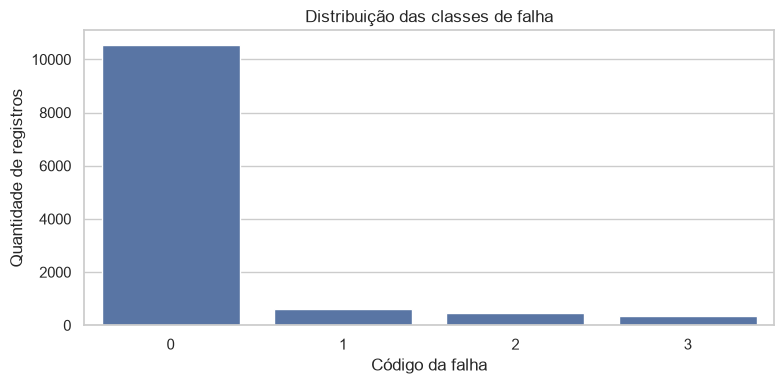

In [33]:
# Confere a quantidade de registros por classe do alvo
if "tipo_falha" in df_tratamento.columns:
    display(
        df_tratamento["tipo_falha"]
        .value_counts(dropna=False)
        .sort_index()
        .rename_axis("tipo_falha")
        .to_frame("quantidade")
    )

    # Visualiza o desbalanceamento das classes
    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df_tratamento,
        x="tipo_falha"
    )

    plt.title("Distribuição das classes de falha")
    plt.xlabel("Código da falha")
    plt.ylabel("Quantidade de registros")
    plt.tight_layout()
    plt.show()

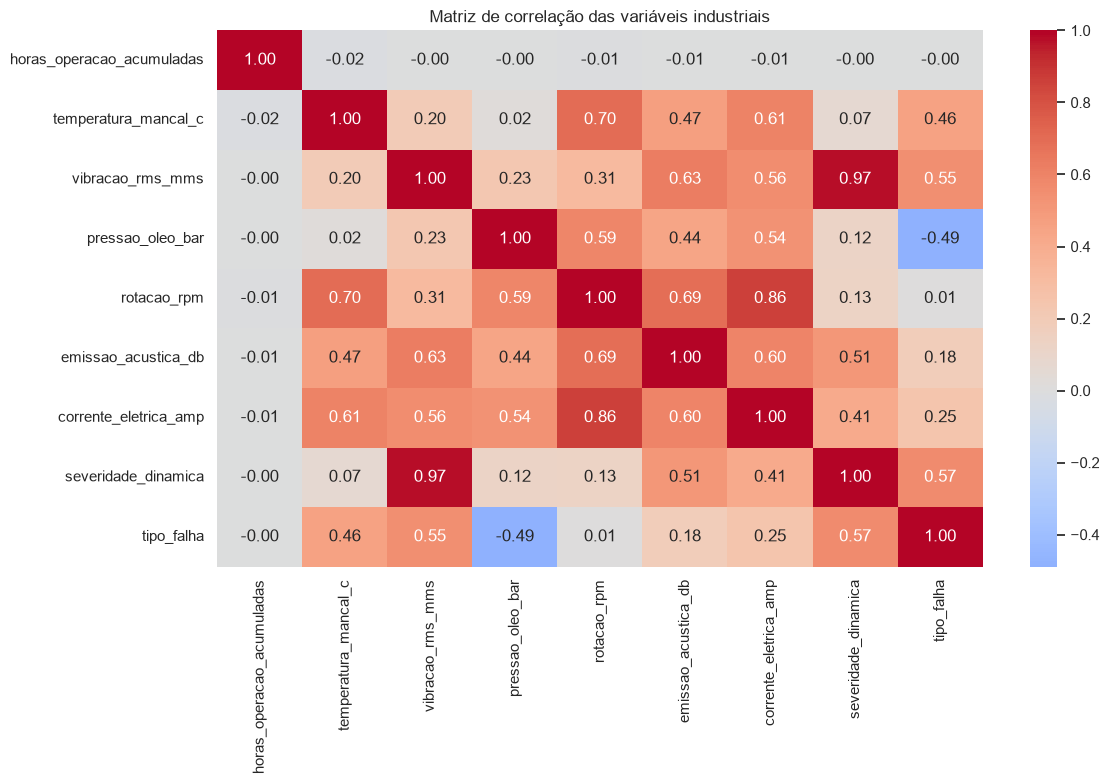

In [34]:
# Seleciona variáveis numéricas originais e derivadas
COLUNAS_CORRELACAO = [
    coluna for coluna in [
        "horas_operacao_acumuladas",
        "temperatura_mancal_c",
        "vibracao_rms_mms",
        "pressao_oleo_bar",
        "rotacao_rpm",
        "emissao_acustica_db",
        "corrente_eletrica_amp",
        "severidade_dinamica",
        "tipo_falha",
    ]
    if coluna in df_tratamento.columns
]

# Calcula as correlações lineares entre as variáveis
matriz_correlacao = df_tratamento[
    COLUNAS_CORRELACAO
].corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    matriz_correlacao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlação das variáveis industriais")
plt.tight_layout()
plt.show()

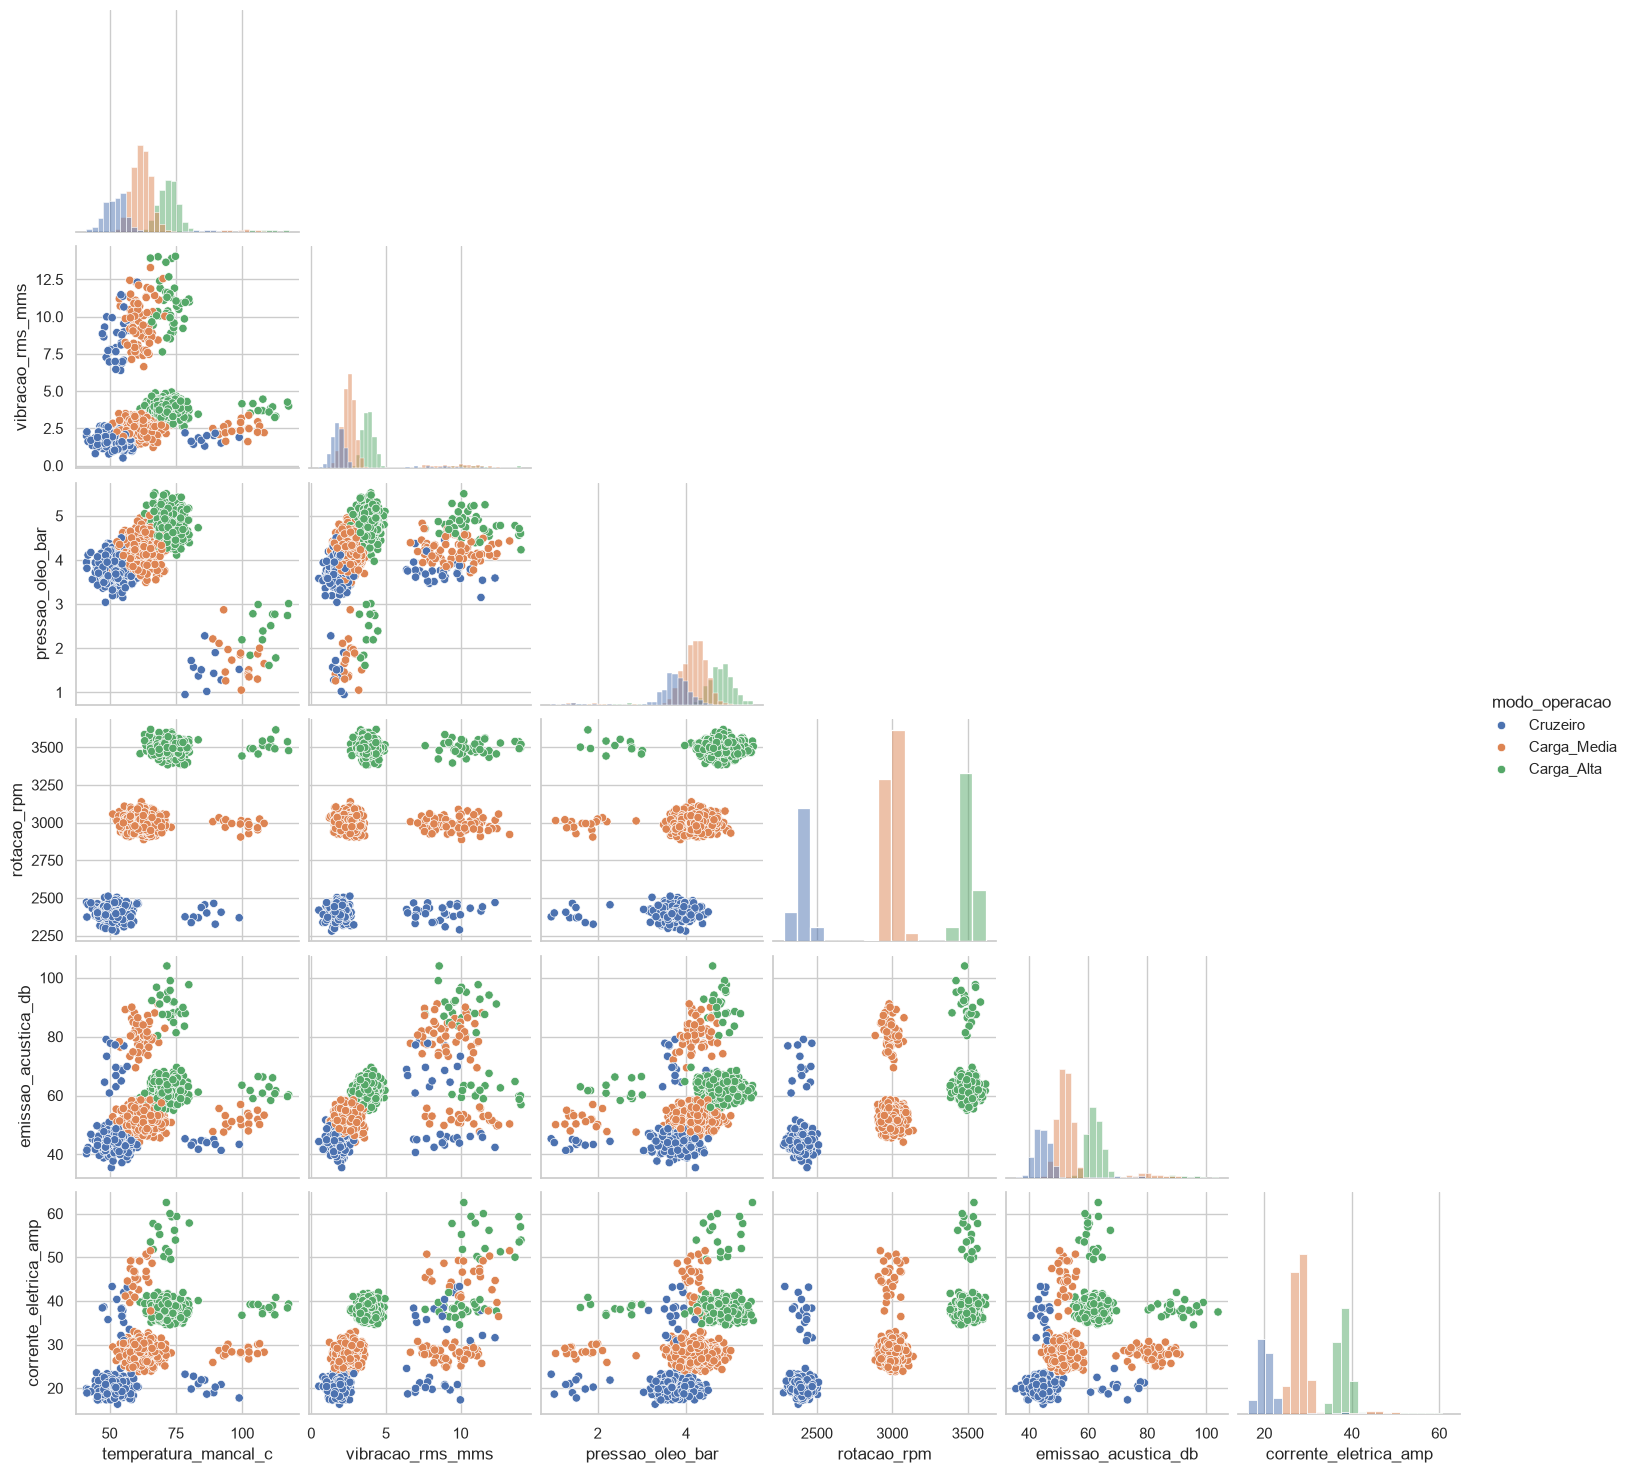

In [35]:
# Seleciona as variáveis para a análise visual conjunta
COLUNAS_PAIRPLOT = [
    coluna for coluna in [
        "temperatura_mancal_c",
        "vibracao_rms_mms",
        "pressao_oleo_bar",
        "rotacao_rpm",
        "emissao_acustica_db",
        "corrente_eletrica_amp",
    ]
    if coluna in df_tratamento.columns
]

# Amostra limitada para reduzir o custo computacional da visualização
dados_pairplot = df_tratamento[
    COLUNAS_PAIRPLOT + ["modo_operacao"]
].dropna().sample(
    n=min(1500, len(df_tratamento.dropna(
        subset=COLUNAS_PAIRPLOT + ["modo_operacao"]
    ))),
    random_state=42
)

# Compara distribuições e relações entre sensores por regime operacional
sns.pairplot(
    dados_pairplot,
    hue="modo_operacao",
    diag_kind="hist",
    corner=True
)

plt.show()

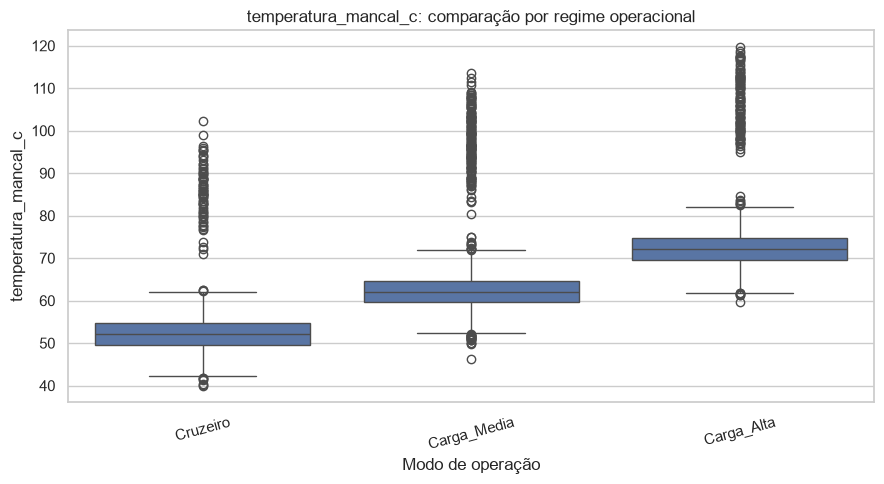

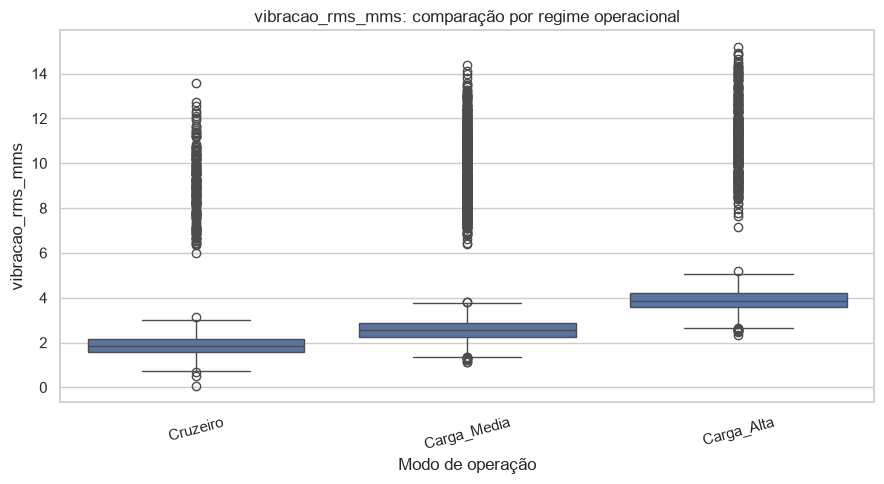

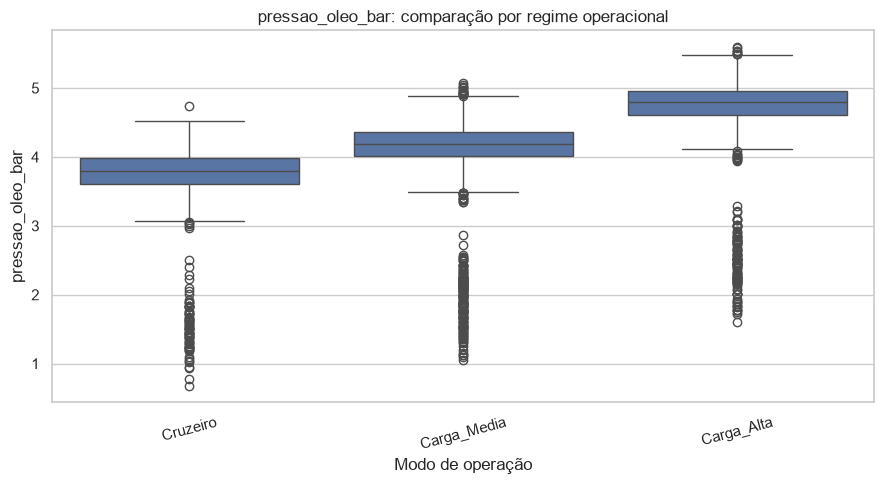

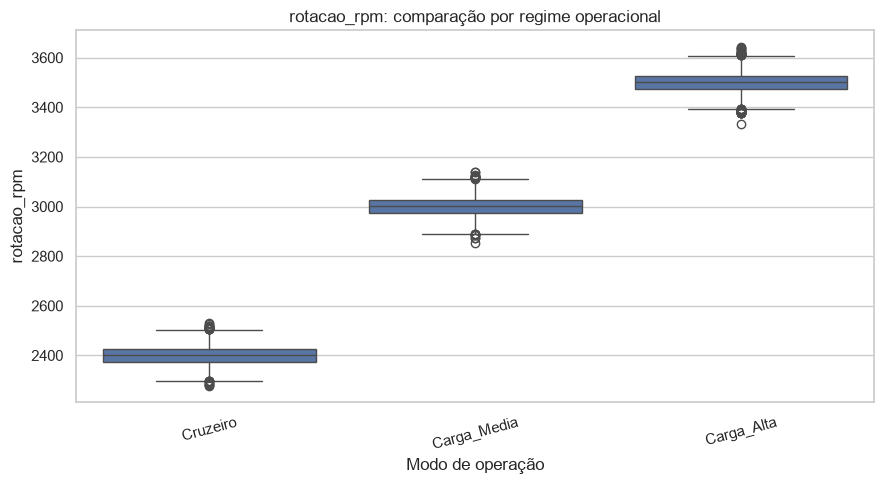

In [36]:
# Verifica a distribuição de temperatura e vibração por regime
COLUNAS_REGIME = [
    coluna for coluna in [
        "temperatura_mancal_c",
        "vibracao_rms_mms",
        "pressao_oleo_bar",
        "rotacao_rpm",
    ]
    if coluna in df_tratamento.columns
]

for coluna in COLUNAS_REGIME:
    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df_tratamento,
        x="modo_operacao",
        y=coluna
    )

    plt.title(f"{coluna}: comparação por regime operacional")
    plt.xlabel("Modo de operação")
    plt.ylabel(coluna)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

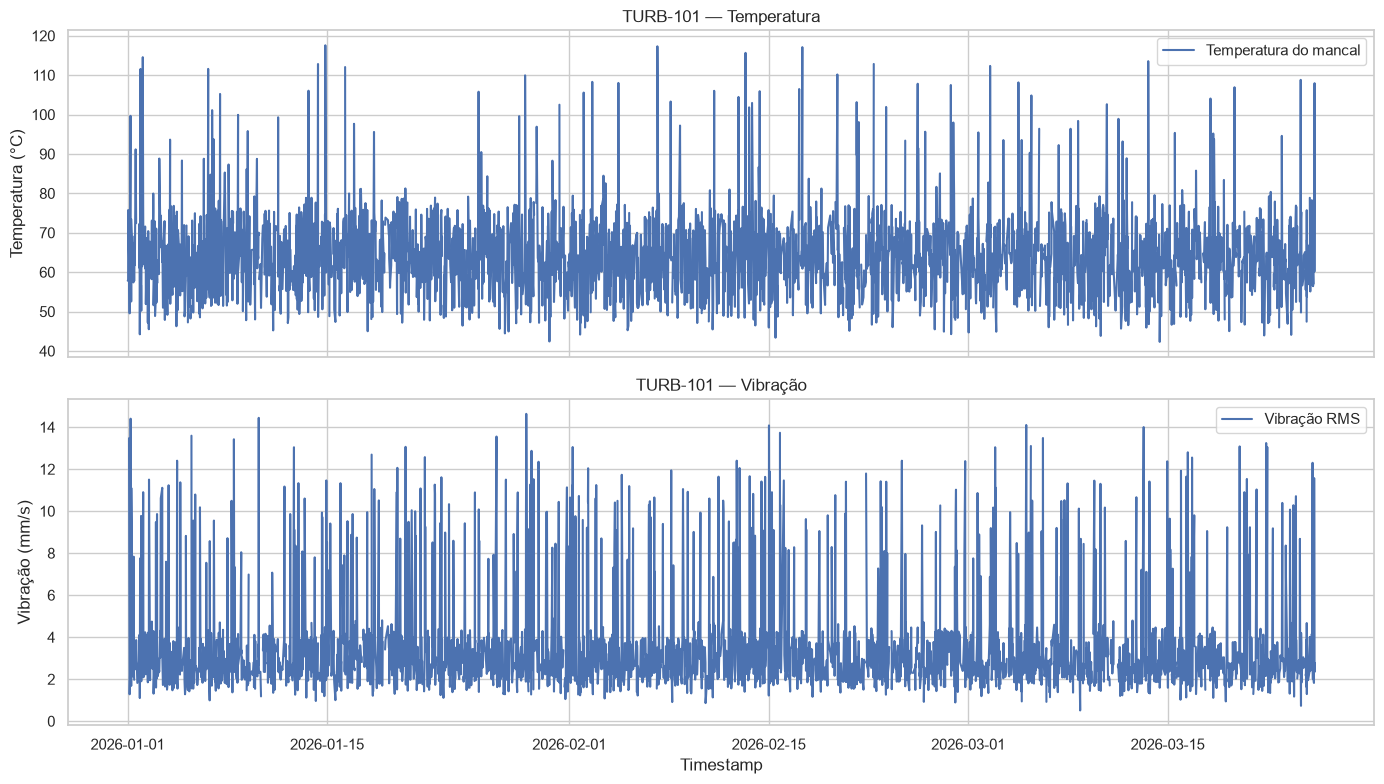

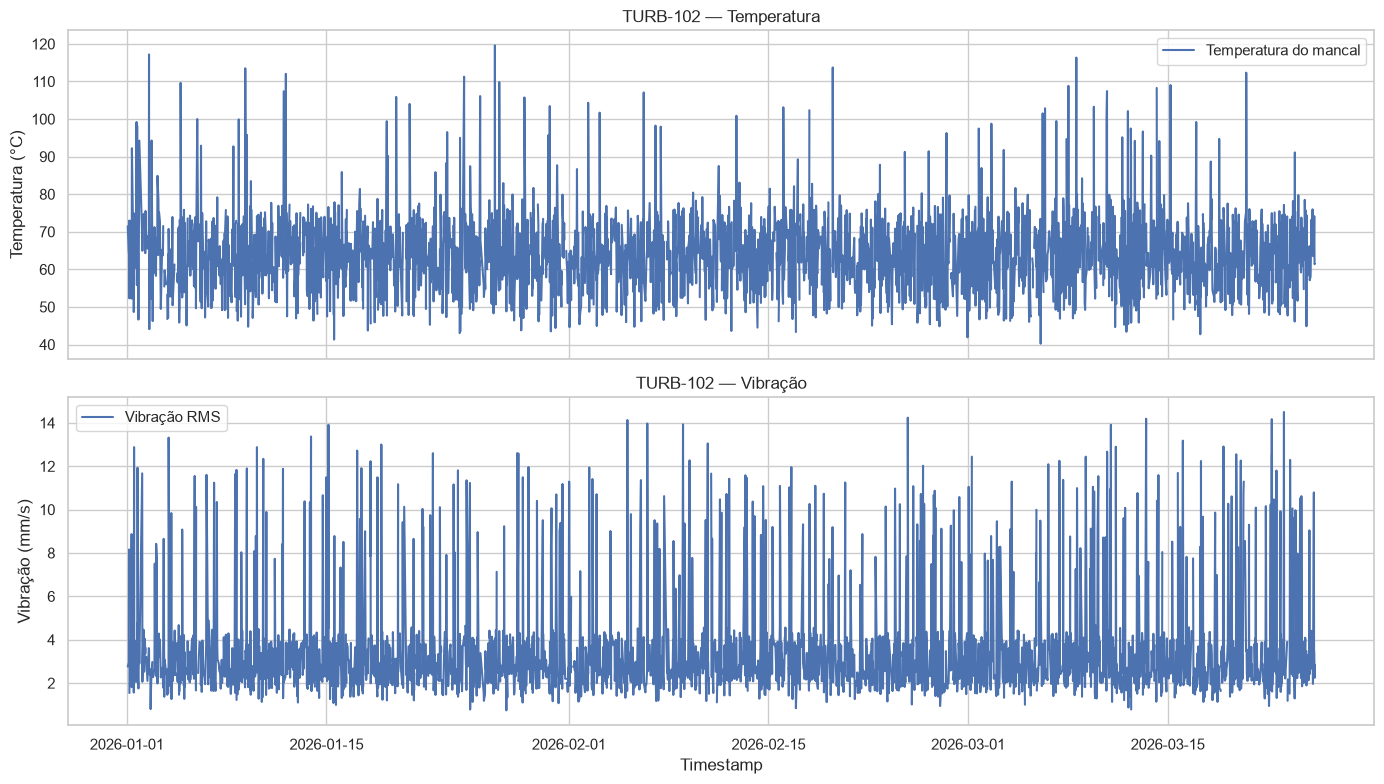

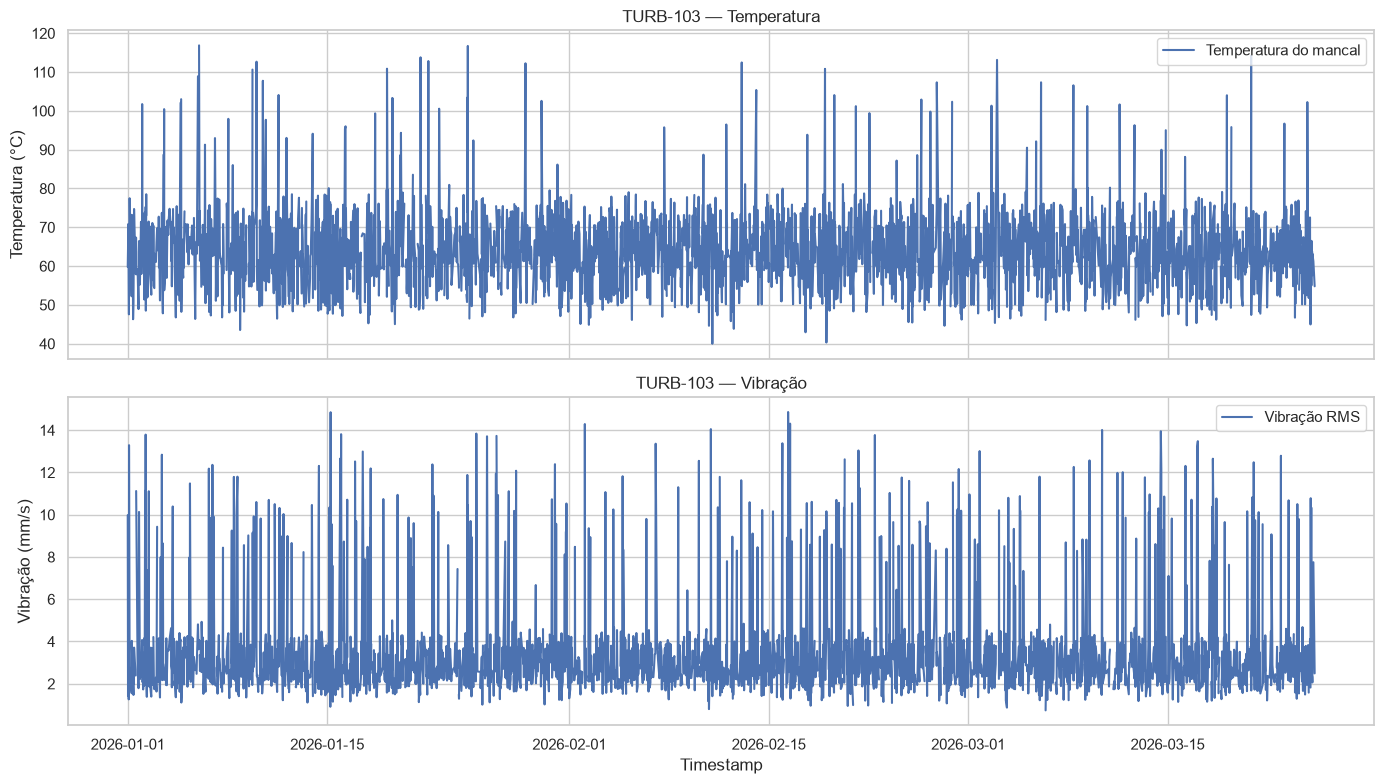

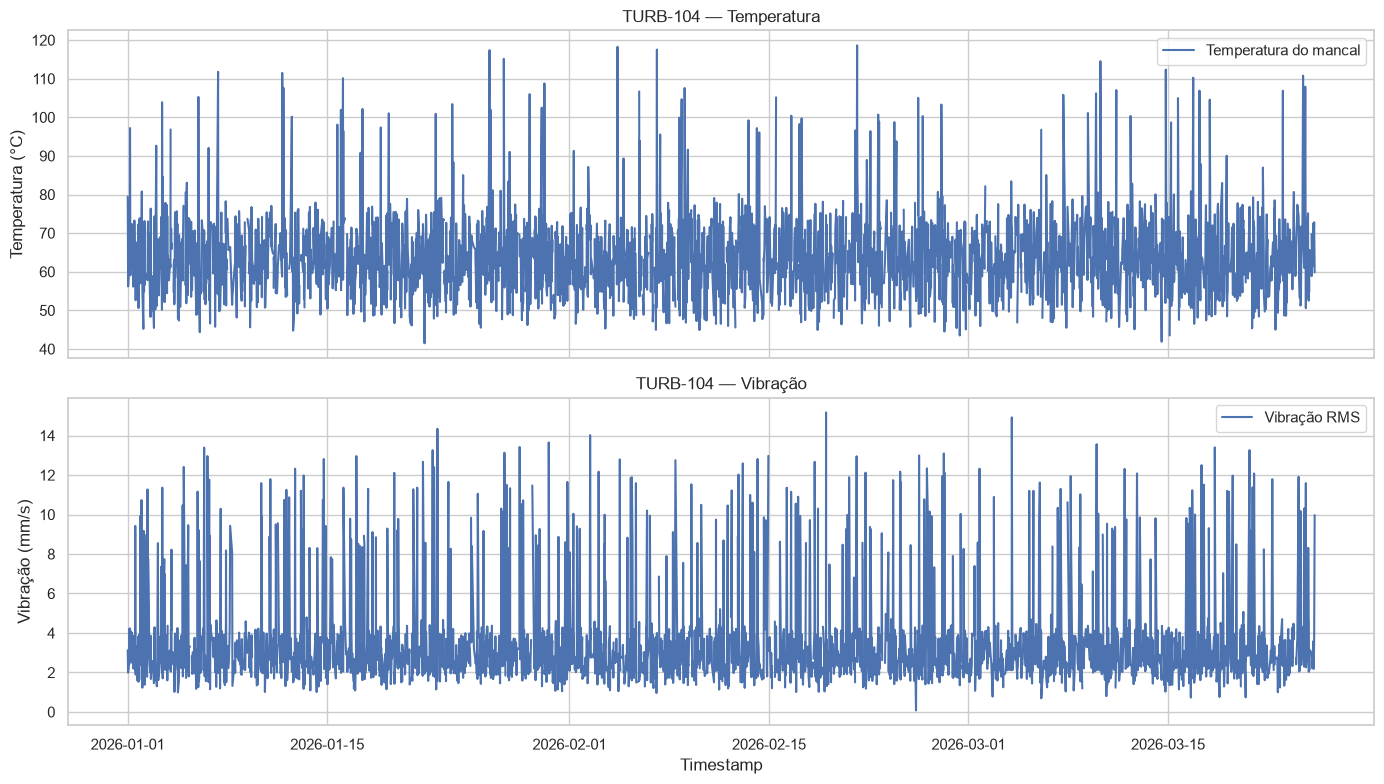

In [37]:
# Lista os equipamentos disponíveis no dataset
equipamentos = sorted(
    df_tratamento["id_equipamento"].dropna().unique()
)

# Exibe a evolução temporal de temperatura e vibração por equipamento
for equipamento in equipamentos:
    dados_equipamento = (
        df_tratamento[
            df_tratamento["id_equipamento"] == equipamento
        ]
        .sort_values("timestamp")
    )

    fig, eixos = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(14, 8),
        sharex=True
    )

    # Evolução da temperatura
    eixos[0].plot(
        dados_equipamento["timestamp"],
        dados_equipamento["temperatura_mancal_c"],
        label="Temperatura do mancal"
    )

    eixos[0].set_title(f"{equipamento} — Temperatura")
    eixos[0].set_ylabel("Temperatura (°C)")
    eixos[0].legend()

    # Evolução da vibração
    eixos[1].plot(
        dados_equipamento["timestamp"],
        dados_equipamento["vibracao_rms_mms"],
        label="Vibração RMS"
    )

    eixos[1].set_title(f"{equipamento} — Vibração")
    eixos[1].set_ylabel("Vibração (mm/s)")
    eixos[1].set_xlabel("Timestamp")
    eixos[1].legend()

    plt.tight_layout()
    plt.show()

In [38]:
# Ordena os registros antes de salvar
df_tratamento = df_tratamento.sort_values(
    ["id_equipamento", "timestamp"]
).reset_index(drop=True)

# Salva o dataset tratado e enriquecido
df_tratamento.to_csv(
    CAMINHO_TRATADO,
    index=False,
    encoding="utf-8"
)

print("Dataset tratado salvo com sucesso.")
print("Caminho:", CAMINHO_TRATADO)
print("Dimensões finais:", df_tratamento.shape)

Dataset tratado salvo com sucesso.
Caminho: c:\Users\adriel_soares2\Documents\Projeto_Aero\data\processed\dados_sensores_aeromotion_tratados.csv
Dimensões finais: (12000, 20)


In [39]:
# Reabre o arquivo salvo para conferir sua integridade
df_validacao_final = pd.read_csv(
    CAMINHO_TRATADO,
    parse_dates=["timestamp"]
)

# Compara a quantidade de registros
print("Registros originais:", len(df_original))
print("Registros tratados:", len(df_validacao_final))

# Verifica os valores ausentes remanescentes
display(
    df_validacao_final.isna()
    .sum()
    .rename("valores_ausentes")
    .to_frame()
    .sort_values("valores_ausentes", ascending=False)
)

# Verifica as classes presentes no arquivo final
if "tipo_falha" in df_validacao_final.columns:
    print("Classes encontradas:")
    print(
        df_validacao_final["tipo_falha"]
        .value_counts(dropna=False)
        .sort_index()
    )

# Confirma que o arquivo de saída existe
assert CAMINHO_TRATADO.exists()

print("\nValidação final concluída.")

Registros originais: 12000
Registros tratados: 12000


,valores_ausentes
temperatura_mancal_c_std_1h,3218
vibracao_rms_mms_std_1h,3188
emissao_acustica_db,484
temperatura_mancal_c,467
vibracao_rms_mms,397
severidade_dinamica,397
pressao_oleo_bar,328
temperatura_mancal_c_media_1h,133
vibracao_rms_mms_media_1h,113
vibracao_rms_mms_std_6h,6


Classes encontradas:
tipo_falha
0    10560
1      600
2      480
3      360
Name: count, dtype: int64

Validação final concluída.


In [40]:
# Consolida informações para documentar as decisões de pré-processamento
relatorio_tratamento = pd.DataFrame({
    "indicador": [
        "Registros originais",
        "Colunas originais",
        "Registros finais",
        "Colunas finais",
        "Timestamps inválidos no CSV original",
        "Valores ausentes no CSV original",
        "Valores ausentes no dataset tratado",
    ],
    "valor": [
        len(df_original),
        len(df_original.columns),
        len(df_tratamento),
        len(df_tratamento.columns),
        df_original["timestamp"].isna().sum()
        if "timestamp" in df_original.columns else np.nan,
        int(df_original.isna().sum().sum()),
        int(df_tratamento.isna().sum().sum()),
    ]
})

display(relatorio_tratamento)

# Exporta o resumo para documentação posterior
CAMINHO_RELATORIO = (
    PASTA_PROCESSED
    / "resumo_tratamento.csv"
)

relatorio_tratamento.to_csv(
    CAMINHO_RELATORIO,
    index=False,
    encoding="utf-8"
)

print("Resumo salvo em:", CAMINHO_RELATORIO)

,indicador,valor
0,Registros originais,12000
1,Colunas originais,11
2,Registros finais,12000
3,Colunas finais,20
4,Timestamps inválidos no CSV original,0
5,Valores ausentes no CSV original,1573
6,Valores ausentes no dataset tratado,8736


Resumo salvo em: c:\Users\adriel_soares2\Documents\Projeto_Aero\data\processed\resumo_tratamento.csv
